# Experiment 2 — Data Preprocessing (Iris Dataset)

**Covers:** Missing values, label encoding, one-hot encoding, standardization, Min-Max scaling, box plot, IQR table, outlier removal and CSV export.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** Missing → Encoding → Scaling → Boxplot → IQR → Remove → Save.

Iris has no missing values, so the fill step leaves the data unchanged (the code is still shown because the manual requires it).

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

df = pd.read_csv("Iris.csv")

## 1. Missing values

In [2]:
print(df.shape)
print(pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": df.isnull().mean() * 100
}))

num = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
cat = ["Species"]

for col in num:
    df[col] = df[col].fillna(df[col].median())

for col in cat:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df[num + cat].isnull().sum())

(150, 6)
               Missing  Percent
Id                   0      0.0
SepalLengthCm        0      0.0
SepalWidthCm         0      0.0
PetalLengthCm        0      0.0
PetalWidthCm         0      0.0
Species              0      0.0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


## 2. Encoding (one-hot and label encoding)

In [3]:
print(pd.get_dummies(df[cat], drop_first=True, dtype=int).head())

df["Species_encoded"] = LabelEncoder().fit_transform(df["Species"])
print(df[["Species", "Species_encoded"]].drop_duplicates())

   Species_Iris-versicolor  Species_Iris-virginica
0                        0                       0
1                        0                       0
2                        0                       0
3                        0                       0
4                        0                       0


             Species  Species_encoded
0        Iris-setosa                0
50   Iris-versicolor                1
100   Iris-virginica                2


## 3. Scaling (standardization and Min-Max)

In [4]:
std = pd.DataFrame(StandardScaler().fit_transform(df[num]), columns=num)
mm = pd.DataFrame(MinMaxScaler().fit_transform(df[num]), columns=num)

print(std.agg(["mean", "std"]).round(2))
print(mm.agg(["min", "max"]))

      SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
mean           -0.0          -0.0            0.0          -0.0
std             1.0           1.0            1.0           1.0
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
min            0.0           0.0            0.0           0.0
max            1.0           1.0            1.0           1.0


## 4. Box plot

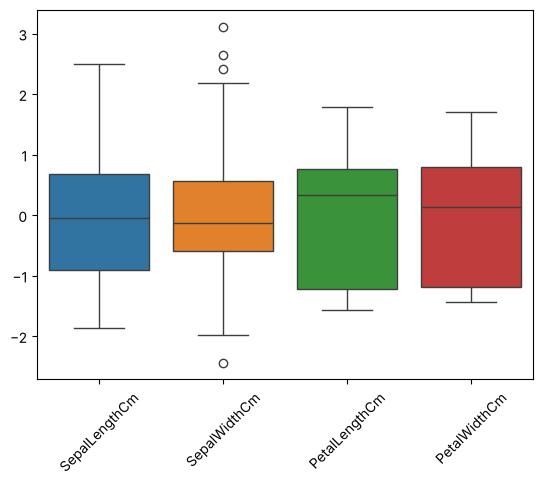

In [5]:
sns.boxplot(data=std)
plt.xticks(rotation=45)
plt.show()

## 5. IQR table

In [6]:
rows = []
for col in num:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, count])

table = pd.DataFrame(rows, columns=[
    "Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"
])
print(table)

          Column   Q1   Q3  IQR  Lower  Upper  Outliers
0  SepalLengthCm  5.1  6.4  1.3   3.15   8.35         0
1   SepalWidthCm  2.8  3.3  0.5   2.05   4.05         4
2  PetalLengthCm  1.6  5.1  3.5  -3.65  10.35         0
3   PetalWidthCm  0.3  1.8  1.5  -1.95   4.05         0


## 6. Remove outliers from `SepalWidthCm` and save

In [7]:
low = table.set_index("Column").loc["SepalWidthCm", "Lower"]
high = table.set_index("Column").loc["SepalWidthCm", "Upper"]

clean = df[df["SepalWidthCm"].between(low, high)]
print("Before:", len(df), "After:", len(clean))

clean.to_csv("clean.csv", index=False)
print("Saved clean.csv")

Before: 150 After: 146
Saved clean.csv


## Result / Conclusion
- No missing values, so median / mode filling leaves the data unchanged.
- `Species` is one-hot encoded (2 columns with `drop_first=True`) and label encoded (setosa = 0, versicolor = 1, virginica = 2).
- After StandardScaler every feature has mean 0 and std 1; after MinMaxScaler every feature lies in [0, 1].
- The IQR rule finds outliers only in `SepalWidthCm` (4 values outside [2.05, 4.05]); removing them leaves 146 of 150 rows, saved as `clean.csv`.